In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
df_encoded=pd.read_csv("../data/processed.csv")
x=df_encoded.drop("median_house_value",axis=1)
y=df_encoded["median_house_value"]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.1,random_state=42)
print("x_train shape",x_train.shape)
print("y_train shape",y_train.shape)
print("x_test shape",x_test.shape)
print("y_test shape",y_test.shape)

x_train shape (15848, 13)
y_train shape (15848,)
x_test shape (1761, 13)
y_test shape (1761,)


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor,GradientBoostingRegressor
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
def evaluate_model(true,predicted):
    mae=mean_absolute_error(true,predicted)
    mse=mean_squared_error(true,predicted)
    rmse=np.sqrt(mean_squared_error(true,predicted))
    r2=r2_score(true,predicted)
    return mae,rmse,r2

In [3]:
models={
    "LR":LinearRegression(),
    "RF":RandomForestRegressor(),
    "Adaboost":AdaBoostRegressor(),
    "GradBoost":GradientBoostingRegressor()
}


In [4]:
model_results={}
for i in range(len(list(models))):
    model=list(models.values())[i]
    model.fit(x_train,y_train)
    y_train_pred=model.predict(x_train)
    y_test_pred=model.predict(x_test)

    model_train_mae,model_train_rmse,model_train_r2=evaluate_model(y_train,y_train_pred)
    model_test_mae,model_test_rmse,model_test_r2=evaluate_model(y_test,y_test_pred)

    model_results[list(models.keys())[i]]={
        "Train RMSE":model_train_rmse,
        "Train MAE":model_train_mae,
        "Train R2":model_train_r2,
        "Test RMSE":model_test_rmse,
        "Test MAE":model_test_mae,
        "Test R2":model_test_r2
    }
results_df=pd.DataFrame(model_results).T
display(results_df)
    

,Train RMSE,Train MAE,Train R2,Test RMSE,Test MAE,Test R2
LR,0.612784,0.457422,0.623361,0.628508,0.457295,0.615407
RF,0.170973,0.113460,0.970680,0.467579,0.306100,0.787142
Adaboost,0.838476,0.732755,0.294833,0.841197,0.727868,0.311070
GradBoost,0.503230,0.358997,0.745994,0.536648,0.375982,0.719613


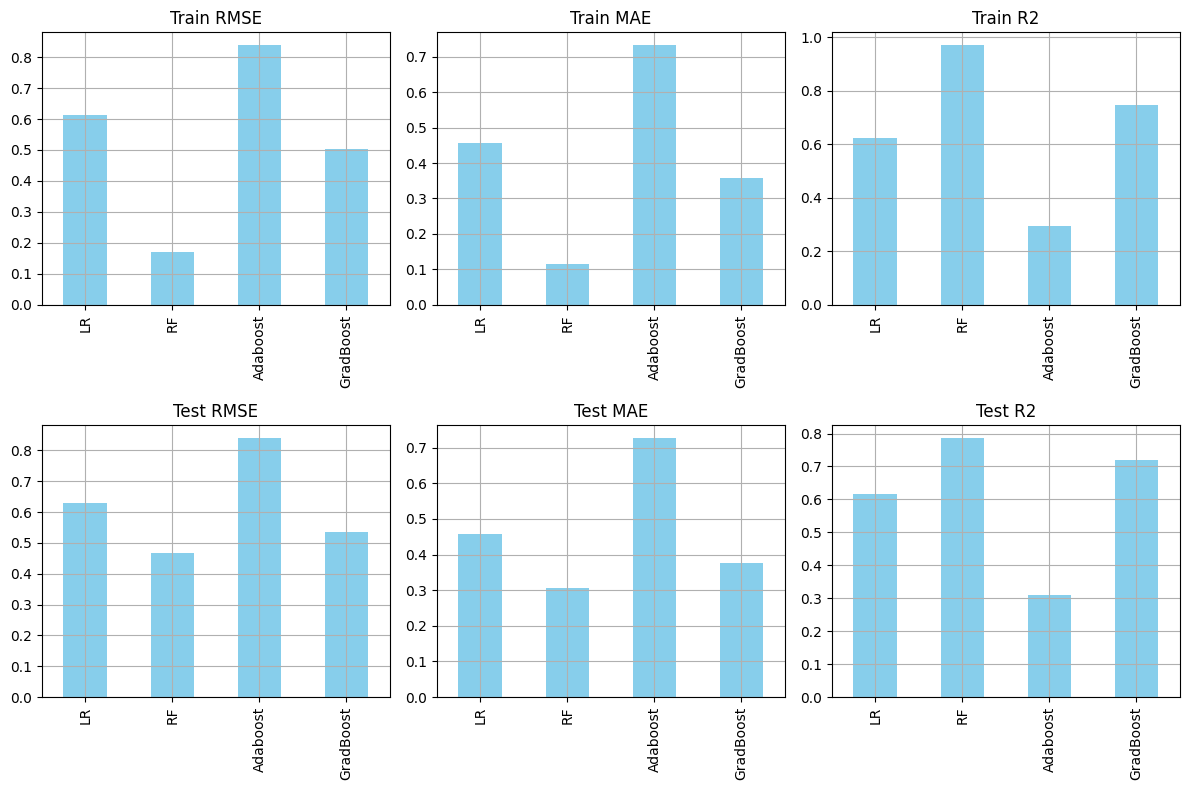

In [5]:
metrics=['Train RMSE','Train MAE','Train R2','Test RMSE','Test MAE','Test R2']
fig,axes=plt.subplots(nrows=2,ncols=3,figsize=(12,8))
axes=axes.flatten()
for i,metric in enumerate(metrics):
    results_df[metric].plot(kind='bar',ax=axes[i],color='SkyBlue')
    axes[i].set_title(metric)
    axes[i].grid()
plt.tight_layout()
plt.savefig('model_metrics.png')
plt.show()

**Fine Tuning using Grid Search**

In [6]:
from sklearn.model_selection import GridSearchCV
param_grid={
    'n_estimators':[100,200],
    'max_depth':[None,10,20]
}
rf_model=RandomForestRegressor()
grid_search=GridSearchCV(rf_model,param_grid,cv=5,scoring='r2')
grid_search.fit(x_train,y_train)
print("Best parameters for Random Forest : ",grid_search.best_params_)
print("Best R2 Score for Random Forest : ",grid_search.best_score_)


Best parameters for Random Forest :  {'max_depth': None, 'n_estimators': 200}
Best R2 Score for Random Forest :  0.7846641118293773
